### Section 0 - Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from fredapi import Fred
from dotenv import load_dotenv
import os

In [2]:
#Loads API key from .env file
load_dotenv()
api_key = os.getenv("FRED_API_KEY")
fred = Fred(api_key=api_key)

In [3]:
test_1 = fred.get_series("DGS10", observation_start="2024-01-01", observation_end="2024-01-10")
print(test_1)

2024-01-01     NaN
2024-01-02    3.95
2024-01-03    3.91
2024-01-04    3.99
2024-01-05    4.05
2024-01-08    4.01
2024-01-09    4.02
2024-01-10    4.04
dtype: float64


After importing the relevant packages, I can load the API key from the .env file, and use the fredapi package to connect to the API. After running the second block of code without any errors, I used the get_series function to collect a sample of data between Jan 1-10 2024,from DGS10 for further verification. I can see from the output that it looks consistent with expected yield levels(~4%).

### Section 1 - Data Collection and Validation

In [4]:
try:
    dgs10 = fred.get_series("DGS10", observation_start="1800-01-01")
    dgs10 = dgs10.rename("DGS10")
except Exception as e:
    print(f"Failed to pull DGS10: {e}")

print("Shape:", dgs10.shape)
print(dgs10.head())
print(dgs10.tail())
print("Index type:", type(dgs10.index))
print("Missing values:", dgs10.isna().sum())
print("First 10 missing dates:", dgs10[dgs10.isna()].index[:10].tolist())
print("Date spacing (top 5):")
print(dgs10.index.to_series().diff().value_counts().head())
print("Min/Max:", dgs10.min(), "/", dgs10.max())

dgs10.to_csv("raw_dgs10.csv")

Shape: (16876,)
1962-01-02    4.06
1962-01-03    4.03
1962-01-04    3.99
1962-01-05    4.02
1962-01-08    4.03
Name: DGS10, dtype: float64
2026-09-02    4.79
2026-09-03    4.77
2026-09-04    4.78
2026-09-07     NaN
2026-09-08    4.80
Name: DGS10, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 720
First 10 missing dates: [Timestamp('1962-02-12 00:00:00'), Timestamp('1962-02-22 00:00:00'), Timestamp('1962-04-20 00:00:00'), Timestamp('1962-05-30 00:00:00'), Timestamp('1962-07-04 00:00:00'), Timestamp('1962-09-03 00:00:00'), Timestamp('1962-10-12 00:00:00'), Timestamp('1962-11-06 00:00:00'), Timestamp('1962-11-12 00:00:00'), Timestamp('1962-11-22 00:00:00')]
Date spacing (top 5):
1 days    13500
3 days     3375
Name: count, dtype: int64
Min/Max: 0.52 / 15.84


What we can see from the output:

- I set `observation_start` to 1800-01-01 (deliberately before any real data) so FRED reveals the true start date rather than one I assume - this confirms DGS10 begins 1962-01-02. I rename it to "DGS10" for clarity in later steps.

- Shape (16,860 rows) matches ~64 years of daily, business day data. Index and values are datetime and float, as expected. The 719 missing values are all US federal holidays (confirmed by the first 10 dates), not a data issue.

- Date spacing only shows 1-day and 3-day gaps because `.diff()` checks the index, not values: weekends are excluded from the index (a real 3-day gap), while holidays still exist as rows with a NaN value (no gap at all).

- The min/max values are plausible values so we can confirm that there are no sentinel values. 

In [5]:
try:
    dgs2 = fred.get_series("DGS2", observation_start="1800-01-01")
    dgs2 = dgs2.rename("DGS2")
except Exception as e:
    print(f"Failed to pull DGS2: {e}")

print("Shape:", dgs2.shape)
print(dgs2.head())
print(dgs2.tail())
print("Index type:", type(dgs2.index))
print("Missing values:", dgs2.isna().sum())
print("First 10 missing dates:", dgs2[dgs2.isna()].index[:10].tolist())
print("Date spacing (top 5):")
print(dgs2.index.to_series().diff().value_counts().head())
print("Min/Max:", dgs2.min(), "/", dgs2.max())

dgs2.to_csv("raw_dgs2.csv")

Shape: (13116,)
1976-06-01    7.26
1976-06-02    7.23
1976-06-03    7.22
1976-06-04    7.12
1976-06-07    7.09
Name: DGS2, dtype: float64
2026-09-02    4.39
2026-09-03    4.34
2026-09-04    4.37
2026-09-07     NaN
2026-09-08    4.39
Name: DGS2, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 552
First 10 missing dates: [Timestamp('1976-07-05 00:00:00'), Timestamp('1976-09-06 00:00:00'), Timestamp('1976-10-11 00:00:00'), Timestamp('1976-11-02 00:00:00'), Timestamp('1976-11-11 00:00:00'), Timestamp('1976-11-25 00:00:00'), Timestamp('1976-12-24 00:00:00'), Timestamp('1977-02-21 00:00:00'), Timestamp('1977-04-08 00:00:00'), Timestamp('1977-05-30 00:00:00')]
Date spacing (top 5):
1 days    10492
3 days     2623
Name: count, dtype: int64
Min/Max: 0.09 / 16.95


The same methods are used for DGS2, so we can see that the data starts mid-1976, 14 years after DGS10. This limits the 10Y-2Y analysis. After some research I can see that this is because 2-year treasury notes weren't issued on a regular schedule until the mid-1970s. All the other values check out, so we can move on from here. 

In [6]:
try:
    dgs3mo = fred.get_series("DGS3MO", observation_start="1800-01-01")
    dgs3mo = dgs3mo.rename("DGS3MO")
except Exception as e:
    print(f"Failed to pull DGS3MO: {e}")

print("Shape:", dgs3mo.shape)
print(dgs3mo.head())
print(dgs3mo.tail())
print("Index type:", type(dgs3mo.index))
print("Missing values:", dgs3mo.isna().sum())
print("First 10 missing dates:", dgs3mo[dgs3mo.isna()].index[:10].tolist())
print("Date spacing (top 5):")
print(dgs3mo.index.to_series().diff().value_counts().head())
print("Min/Max:", dgs3mo.min(), "/", dgs3mo.max())

dgs3mo.to_csv("raw_dgs3mo.csv")

Shape: (11746,)
1981-09-01    17.01
1981-09-02    16.65
1981-09-03    16.96
1981-09-04    16.64
1981-09-07      NaN
Name: DGS3MO, dtype: float64
2026-09-02    3.92
2026-09-03    3.89
2026-09-04    3.91
2026-09-07     NaN
2026-09-08    3.94
Name: DGS3MO, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 492
First 10 missing dates: [Timestamp('1981-09-07 00:00:00'), Timestamp('1981-10-12 00:00:00'), Timestamp('1981-11-03 00:00:00'), Timestamp('1981-11-11 00:00:00'), Timestamp('1981-11-26 00:00:00'), Timestamp('1981-12-09 00:00:00'), Timestamp('1981-12-25 00:00:00'), Timestamp('1982-01-01 00:00:00'), Timestamp('1982-02-12 00:00:00'), Timestamp('1982-02-15 00:00:00')]
Date spacing (top 5):
1 days    9396
3 days    2349
Name: count, dtype: int64
Min/Max: 0.0 / 17.01


This is the same check as we did before for DGS10 and DGS2, all the values check out perfectly, and we can see that the data started in 1981, a lot later than the other two, so this will limit our comparision capabilities, as the date ranges differ too much. However, I would still like to use the 10Y-3MO comparision as it's the version the NY Fed's own recession model actually uses and has been shown to outperform 10Y-2Y empirically. 

In [7]:
try:
    usrec = fred.get_series("USREC", observation_start="1800-01-01")
    usrec = usrec.rename("USREC")
except Exception as e:
    print(f"Failed to pull USREC: {e}")

print("Shape:", usrec.shape)
print(usrec.head())
print(usrec.tail())
print("Index type:", type(usrec.index))
print("Missing values:", usrec.isna().sum())
print("Unique values:", usrec.unique())
print("Date spacing (top 5):")
print(usrec.index.to_series().diff().value_counts().head())

usrec.to_csv("raw_usrec.csv")

Shape: (2061,)
1854-12-01    1.0
1855-01-01    0.0
1855-02-01    0.0
1855-03-01    0.0
1855-04-01    0.0
Name: USREC, dtype: float64
2026-04-01    0.0
2026-05-01    0.0
2026-06-01    0.0
2026-07-01    0.0
2026-08-01    0.0
Name: USREC, dtype: float64
Index type: <class 'pandas.DatetimeIndex'>
Missing values: 0
Unique values: [1. 0.]
Date spacing (top 5):
31 days    1202
30 days     686
28 days     130
29 days      42
Name: count, dtype: int64


USREC goes back to **1854** - NBER's recession dating extends way further than the other three yield series, so this isn't the limiting factor for our date range. No missing values, since it's a monthly series with no daily weekend or holiday gaps. The `[1. 0.]` unique values confirm it's a binary flag, as expected. Date spacing (28–31 days) confirms monthly frequency.

### Section 2 - Exploratory Data Analysis (Raw Series)

Before I combine or transform the four series in any way, Im going to look at each one on its own. This is intentional as it'll be easier to catch something odd like an unexpected large gap, or a suspicious value, if I look at the raw data first instead of after I've merged and reshaped everything. Whatever I decide to do in the wrangling step (Section 3) will be informed by what I actually see here.

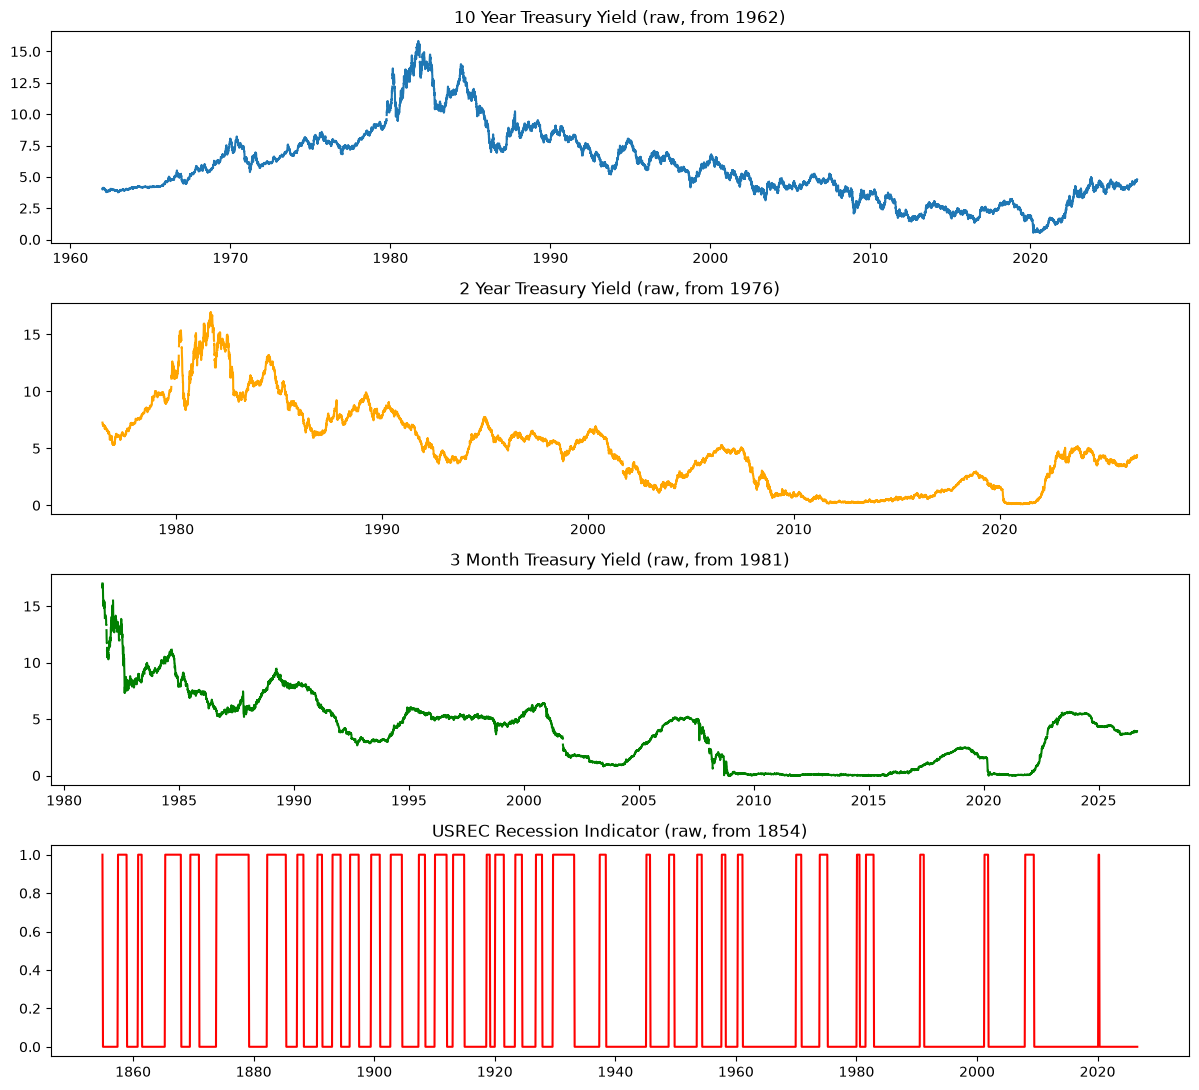

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=False)
axes[0].plot(dgs10.index, dgs10.values)
axes[0].set_title(f"10 Year Treasury Yield (raw, from {dgs10.index.min().year})")
axes[1].plot(dgs2.index, dgs2.values, color="orange")
axes[1].set_title(f"2 Year Treasury Yield (raw, from {dgs2.index.min().year})")
axes[2].plot(dgs3mo.index, dgs3mo.values, color="green")
axes[2].set_title(f"3 Month Treasury Yield (raw, from {dgs3mo.index.min().year})")
axes[3].plot(usrec.index, usrec.values, color="red")
axes[3].set_title(f"USREC Recession Indicator (raw, from {usrec.index.min().year})")
plt.tight_layout()
plt.show()

Before combining the four series, I plotted each one on its own to get a feel for its shape and range. I deliberately didn't share the x-axis across the four subplots; they all started at different points, as we can see in section 1, so sharing one x-axis would have stretched every subplot back to whichever series started earliest, leaving misleading empty space on the others. Each subplot's title showed its actual start year, read directly from the data. There are no large gaps in the data or any unexpected values on all four of the plots, so I can safely move on from here. 

In [9]:
print("DGS10 describe:")
print(dgs10.describe())
print()

print("DGS2 describe:")
print(dgs2.describe())
print()

print("DGS3MO describe:")
print(dgs3mo.describe())
print()

print("USREC describe:")
print(usrec.describe())

DGS10 describe:
count    16156.000000
mean         5.805274
std          2.929183
min          0.520000
25%          3.900000
50%          5.400000
75%          7.530000
max         15.840000
Name: DGS10, dtype: float64

DGS2 describe:
count    12564.000000
mean         4.952549
std          3.653260
min          0.090000
25%          1.710000
50%          4.615000
75%          7.100000
max         16.950000
Name: DGS2, dtype: float64

DGS3MO describe:
count    11254.000000
mean         3.828125
std          3.110304
min          0.000000
25%          0.940000
50%          3.920000
75%          5.580000
max         17.010000
Name: DGS3MO, dtype: float64

USREC describe:
count    2061.000000
mean        0.280932
std         0.449563
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: USREC, dtype: float64


I also check basic summary statistics for each series count, mean, min, max, and quartiles. This is an additional check before moving on. Yields should fall in a plausible range (roughly 0-16% historically), and USREC should only ever be 0 or 1. Anything outside these ranges would flag a data issue worth investigating before I build anything on top of it. As we can see, everything is in range and we can move on to the next section from here.

### Section 3 - Data Wrangling

Before I can compare the yields or calculate a spread, I need all four series lined up on the same timeline. Right now they don't match because the yields are daily and USREC is monthly, and each series starts at a different point in history. This section resamples everything to monthly and combines them into two aligned tables to work with going forward.

In [10]:
monthly_dgs10 = dgs10.resample("MS").mean()
monthly_dgs2 = dgs2.resample("MS").mean()
monthly_dgs3mo = dgs3mo.resample("MS").mean()
monthly_usrec = usrec.resample("MS").last()

- I resampled the daily yield series (10Y, 2Y, 3M) to monthly using `"MS"` 
(represents month-start), which averages each month's daily values into a single number 
and labels it with the first day of that month in one step.
- I used `"MS"` specifically because it already labels each row with the first of the month, matching USREC's own date convention. This can be seen in the data collection and validation of USREC in section 1.
- USREC is already monthly, so I just took `.last()` per month, which takes the last value in that month, and therefore chooses the only value in the month.

In [11]:
df_full = pd.concat([monthly_dgs10, monthly_dgs2, monthly_usrec], axis=1, sort=False)
df_full = df_full.dropna()

df_common = pd.concat([monthly_dgs10, monthly_dgs2, monthly_dgs3mo, monthly_usrec], axis=1, sort=False)
df_common = df_common.dropna()

print(f"df_full   (10Y-2Y only): {df_full.index.min().date()} to {df_full.index.max().date()} ({df_full.shape[0]} months)")
print(f"df_common (10Y-2Y-3M)  : {df_common.index.min().date()} to {df_common.index.max().date()} ({df_common.shape[0]} months)")

df_full   (10Y-2Y only): 1976-06-01 to 2026-08-01 (603 months)
df_common (10Y-2Y-3M)  : 1981-09-01 to 2026-08-01 (540 months)


- I created two separate combined tables instead of one:
  - `df_full` - only 10Y and 2Y, so it keeps the longest possible history (starting in 1976-06-01, where DGS2 begins). This is why `dropna()` was used, as DGS10 starts in 1962, a lot earlier, so we have to use the common months available between the two.
  - `df_common` - includes 3M as well, so `dropna()` truncates it to 1981-09-01 where DGS3MO data actually starts, which is later than 10Y and 2Y.
- I split them this way because merging all three yields into a single table and dropping missing rows would truncate the whole dataset to 3M's shorter history, losing several years of the otherwise valid 10Y-2Y data. `df_full` avoids that, `df_common` exists specifically for a fair 10Y-2Y vs 10Y-3M comparison later, where both spreads need to be tested over the same window.
- I printed out the date range of the two datasets, and how many months they cover. As you can see, df_common has a lot less months that df_full due to the shorter date range.

### Section 4 - Exploratory Data Analysis (Combined Datasets)

Before calculating any spreads, I'm going to check both merged datasets from Section 3, first `df_full` (the main dataset used for the rest of the notebook), then `df_common` (the secondary dataset that also includes DGS3MO for the 10Y-2Y vs 10Y-3MO comparision), to confirm the monthly resampling and series alignment worked correctly.

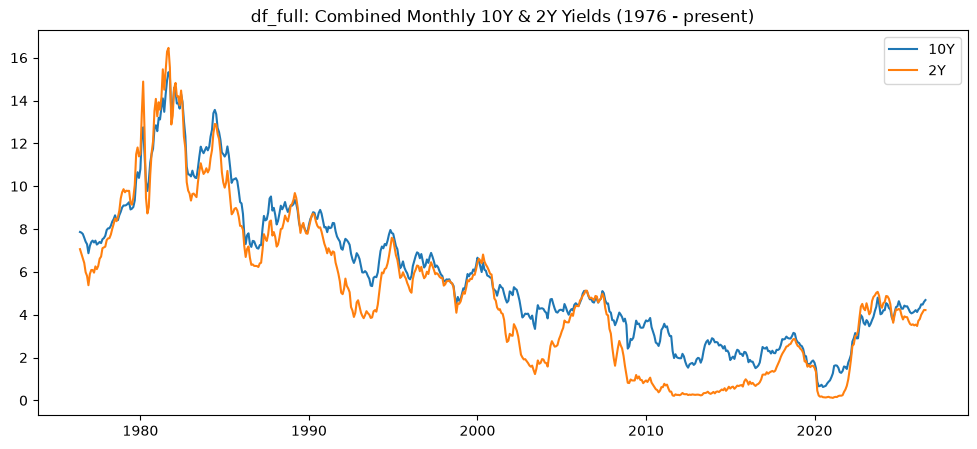

            DGS10        DGS2       USREC
count  603.000000  603.000000  603.000000
mean     5.802229    4.956870    0.096186
std      3.238862    3.655667    0.295091
min      0.623636    0.115263    0.000000
25%      3.390810    1.741667    0.000000
50%      5.087500    4.588000    0.000000
75%      7.858050    7.108789    0.000000
max     15.323810   16.457619    1.000000

Correlation matrix (df_full):
          DGS10      DGS2     USREC
DGS10  1.000000  0.972386  0.206540
DGS2   0.972386  1.000000  0.182303
USREC  0.206540  0.182303  1.000000


In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_full.index, df_full["DGS10"], label="10Y")
ax.plot(df_full.index, df_full["DGS2"], label="2Y")
ax.legend()
ax.set_title("df_full: Combined Monthly 10Y & 2Y Yields (1976 - present)")
plt.show()

print(df_full.describe())
print()
print("Correlation matrix (df_full):")
print(df_full.corr())

- I plotted the 10Y and 2Y yields together using df_full, the main dataset the rest of the notebook is built on. This checks that the monthly resampling and series merge from Section 3 worked correctly. The two lines follow each other closely over time, which is what I'd expect from two treasury yields, so the alignment looks correct. We can also see that the two series have a strong positive relationship using the correlation matrix, as the correlation between the two series is close to 1.

- The summary statistics(using `.describe()`) shows both yields sitting in a reasonable range: DGS10 averages 5.80% (ranging 0.62%-15.32%) and DGS2 averages 4.96% (ranging 0.12%-16.46%). USREC averages 0.096, meaning about 9.6% of months in this sample were recession months. Nothing here looks off, so I can move on to calculating the spread in Section 5.

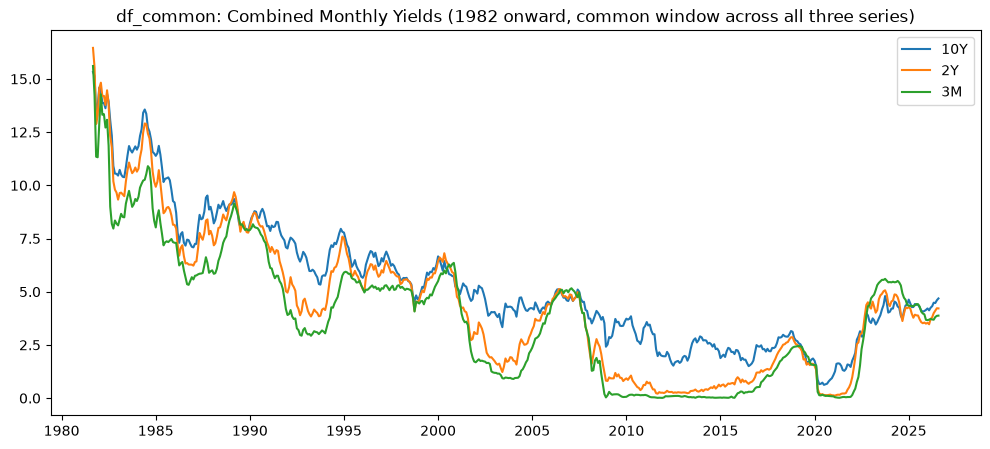

            DGS10        DGS2      DGS3MO       USREC
count  540.000000  540.000000  540.000000  540.000000
mean     5.362932    4.422412    3.830893    0.094444
std      3.050621    3.343466    3.112866    0.292717
min      0.623636    0.115263    0.011429    0.000000
25%      2.909762    1.507808    0.944007    0.000000
50%      4.597392    4.208750    3.943611    0.000000
75%      7.170119    6.276667    5.581750    0.000000
max     15.323810   16.457619   15.607143    1.000000

Correlation matrix:
           DGS10      DGS2    DGS3MO     USREC
DGS10   1.000000  0.967904  0.919083  0.207921
DGS2    0.967904  1.000000  0.981998  0.182076
DGS3MO  0.919083  0.981998  1.000000  0.165046
USREC   0.207921  0.182076  0.165046  1.000000


In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_common.index, df_common["DGS10"], label="10Y")
ax.plot(df_common.index, df_common["DGS2"], label="2Y")
ax.plot(df_common.index, df_common["DGS3MO"], label="3M")
ax.legend()
ax.set_title("df_common: Combined Monthly Yields (1982 onward, common window across all three series)")
plt.show()

print(df_common.describe())
print()
print("Correlation matrix:")
print(df_common.corr())

- I plotted the 10Y, 2Y, and 3M yields together using df_common, the secondary dataset used specifically for the 10Y-2Y vs 10Y-3M comparison later on. This checks that including DGS3MO in the merge and resampling worked correctly. The three lines follow each other closely over time, which is what I'd expect from three treasury yields, so the alignment looks correct. The correlation matrix confirms this, showing all three series have a strong positive relationship with each other (0.92-0.98).

- The summary statistics show all three yields sitting in a reasonable range: DGS10 averages 5.36% (ranging 0.62%-15.32%), DGS2 averages 4.42% (ranging 0.12%-16.46%), and DGS3MO averages 3.83% (ranging 0.01%-15.61%). USREC averages 0.094, meaning about 9.4% of months in this sample were recession months. Nothing here looks off, so I can move on to calculating both spreads in Section 5.